The data is saved in .hdf5 format. Run the code below to understand what is inside these hdf5 files.

In [2]:
import h5py

data_path = '../Data/'
hosthalo_file = 'hosthalo_IC.hdf5'
subhalo_file = 'subhalo_IC.hdf5'

# Open the file in 'r' (read-only) mode so we don't accidentally change anything
with h5py.File(data_path + hosthalo_file, 'r') as f:
    
    # visititems travels through every single folder and file inside the HDF5
    # The 'lambda' is just a quick way to tell Python: 
    # "For every item you find (name and object), do the following..."
    f.visititems(lambda name, obj: print(
        f"Path: {name:30} | Type: {str(type(obj)):20} | Shape: {getattr(obj, 'shape', 'N/A')}"
    ))

Path: Header                         | Type: <class 'h5py._hl.group.Group'> | Shape: N/A
Path: PartType1                      | Type: <class 'h5py._hl.group.Group'> | Shape: N/A
Path: PartType1/Coordinates          | Type: <class 'h5py._hl.dataset.Dataset'> | Shape: (453734, 3)
Path: PartType1/ParticleIDs          | Type: <class 'h5py._hl.dataset.Dataset'> | Shape: (453734,)
Path: PartType1/Velocities           | Type: <class 'h5py._hl.dataset.Dataset'> | Shape: (453734, 3)


In [3]:
with h5py.File(data_path + hosthalo_file, 'r') as f:
    # Access the coordinates dataset
    pos = f['PartType1/Coordinates'][:] 
    
    # Access the first particle's X, Y, Z
    print(f"First particle position: {pos[0]}") 
    
    # Access the total number of particles
    print(f"Total particles: {pos.shape[0]}")

host_x = pos[:, 0]  # X coordinates
host_y = pos[:, 1]  # Y coordinates
host_z = pos[:, 2]  # Z coordinates

First particle position: [ 9942.388 10096.897 10112.499]
Total particles: 453734


In [ ]:
with h5py.File(data_path + subhalo_file, 'r') as f:
    # Access the coordinates dataset
    pos = f['PartType1/Coordinates'][:] 
    
    # Access the first particle's X, Y, Z
    print(f"First particle position: {pos[0]}") 
    
    # Access the total number of particles
    print(f"Total particles: {pos.shape[0]}")

sub_x = pos[:, 0]  
sub_y = pos[:, 1]  
sub_z = pos[:, 2]  

First particle position: [10646.522 10028.274  9970.077]
Total particles: 41212


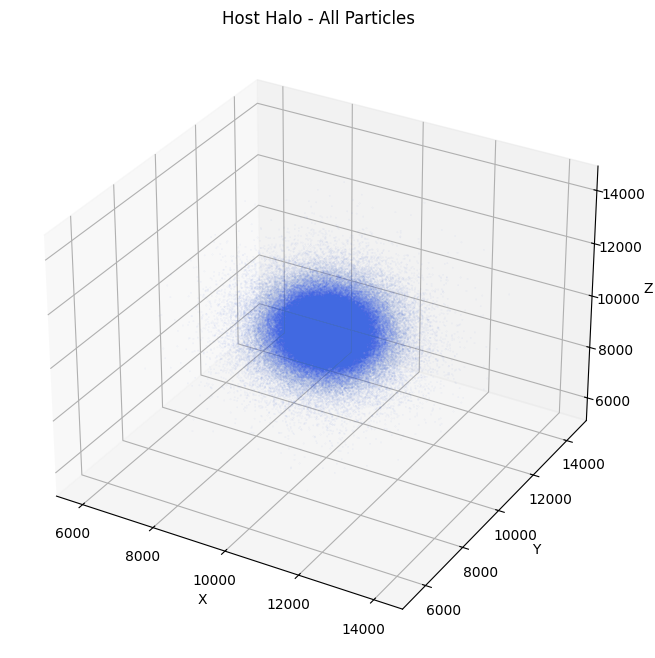

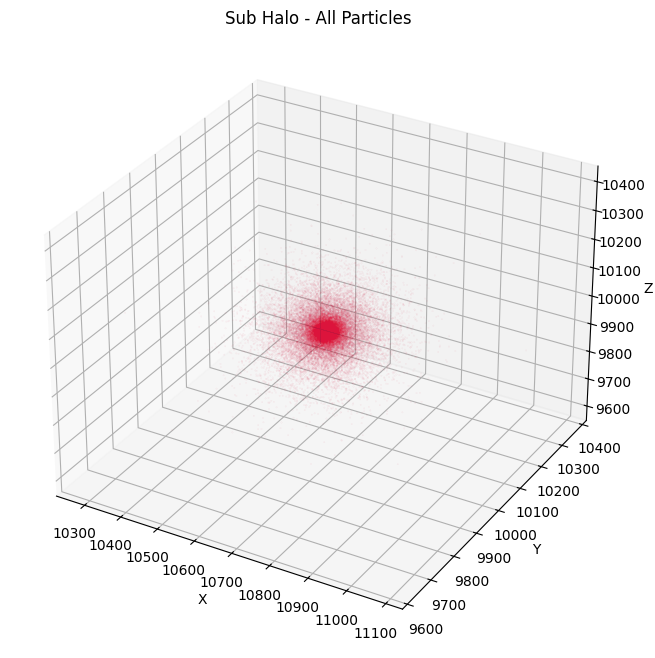

In [7]:
import matplotlib.pyplot as plt

# Create the first figure for the Host Halo
fig1 = plt.figure(figsize=(10, 8))
ax1 = fig1.add_subplot(111, projection='3d')

# Plot all points: s=0.01 (tiny dots), alpha=0.2 (very transparent)
ax1.scatter(host_x, host_y, host_z, s=0.01, c='royalblue', alpha=0.2)

ax1.set_title('Host Halo - All Particles')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')

plt.show()

# Create a second separate figure for the Sub Halo
fig2 = plt.figure(figsize=(10, 8))
ax2 = fig2.add_subplot(111, projection='3d')

# Plot all points for the subhalo
ax2.scatter(sub_x, sub_y, sub_z, s=0.01, c='crimson', alpha=0.2)

ax2.set_title('Sub Halo - All Particles')
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_zlabel('Z')

plt.show()

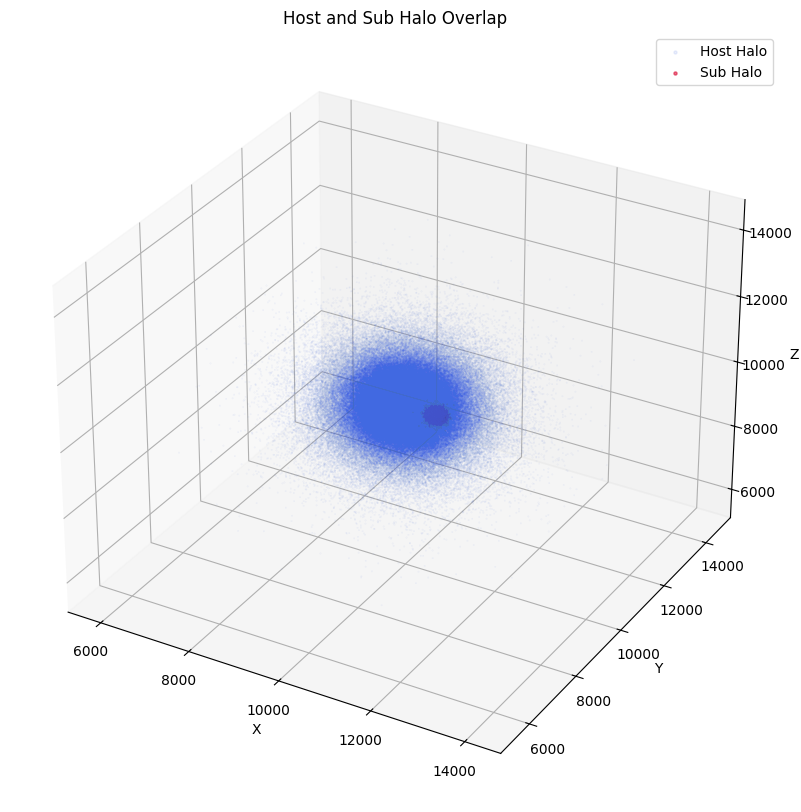

In [15]:
# Create one figure and one set of 3D axes
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Plot the Host Halo particles (Blue)
# We use a very low alpha (transparency) so we can see through the host
ax.scatter(host_x, host_y, host_z, s=0.05, c='royalblue', alpha=0.1, label='Host Halo')

# Plot the Sub Halo particles (Red)
# We use a slightly higher alpha or different color to make it "pop"
ax.scatter(sub_x, sub_y, sub_z, s=0.05, c='crimson', alpha=0.6, label='Sub Halo')

# Add labels and a legend to tell them apart
ax.set_title('Host and Sub Halo Overlap')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.legend(markerscale=10) # Makes the legend icons big enough to see

# min_range = 9000
# max_range = 11000
# ax.set_xlim(min_range, max_range)
# ax.set_ylim(min_range, max_range)
# ax.set_zlim(min_range, max_range)

plt.show()